# Modelo de recobro: probabilidad de recuperación de titulares en mora

**Autor:** Pablo Blas Hernández · TFM Máster en Big Data, Data Science e IA (UCM - NTIC)

El scorecard de comportamiento (Anexo 1) mira a toda la cartera y responde a una pregunta: ¿quién
va a empezar a retrasarse? Este notebook responde a otra, la del recobro: entre los titulares que
**ya están en mora**, ¿quién se va a recuperar por sí solo y quién no?

Las dos preguntas llevan a decisiones distintas. A quien probablemente se recupere basta con un
recordatorio; a quien probablemente no, conviene ofrecerle pronto un plan de pagos o pasarlo a
una gestión especializada. El modelo sustituye la regla escrita a mano del capítulo 9 por una
decisión basada en datos, y genera alertas para el gestor y para el titular.

**Decisiones de diseño:**

- **Evento:** que el titular **no se recupere** el mes siguiente (sigue en mora o empeora). Se
  mantiene la convención del scorecard: el evento es lo malo y una puntuación alta es buena.
- **Validación fuera de tiempo:** se entrena con los titulares en mora de abril a junio y se evalúa
  con los de julio, observando su situación en agosto.
- **Validación por titular:** un mismo titular aparece en varios meses, así que la validación
  cruzada se hace por titular para que nunca esté a la vez en entrenamiento y en evaluación.
- **Sin fugas:** cada variable usa solo información disponible en el mes de la mora.
- Septiembre no se usa como desenlace, porque la columna PAY_1 se codifica de forma distinta a las
  anteriores (Anexo 1).

In [1]:
# optbinning 0.21.0 declara ortools<9.12, pero en el Python reciente de
# Colab solo existe ortools>=9.12. Instalamos primero las dependencias
# reales y despues optbinning con --no-deps, de modo que ese tope no
# bloquee la instalacion.
#
# scikit-learn fijado en 1.6.1, la misma version que la API y los agentes.

import subprocess, sys, warnings

PAQUETES = [
    "scikit-learn==1.6.1", "ortools>=9.12", "ropwr>=1.0.0",
    "openpyxl",
    "pandas", "numpy", "matplotlib", "seaborn", "scipy",
]

def pip_silencioso(args):
    """Instala sin volcar la salida de pip (evita el ruido de dependencias)."""
    return subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", *args],
        capture_output=True, text=True
    )

print("Instalando dependencias...")
r1 = pip_silencioso(PAQUETES)
r2 = pip_silencioso(["--no-deps", "optbinning==0.21.0"])

if r1.returncode != 0 or r2.returncode != 0:
    print("Hubo un problema en la instalacion:")
    print((r1.stderr or "") + (r2.stderr or ""))
else:
    print("Instalacion completada.\n")

import sklearn, ortools, optbinning
print("scikit-learn:", sklearn.__version__)
print("ortools:     ", ortools.__version__)
print("optbinning:  ", optbinning.__version__)
print("\nTodo listo. Ejecuta las celdas siguientes en orden.")

Instalando dependencias...
Instalacion completada.



(CVXPY) Oct 20 11:29:45 AM: Encountered unexpected exception importing solver HIGHS:
ImportError('/usr/local/lib/python3.13/dist-packages/highspy/_core.cpython-313-x86_64-linux-gnu.so: undefined symbol: _ZN5Highs13releaseMemoryEv')
(CVXPY) Oct 20 11:29:45 AM: Encountered unexpected exception importing solver GLOP:
RuntimeError('Unrecognized new version of ortools (9.15.6755). Expected < 9.12.0. Please open a feature request on cvxpy to enable support for this version.')
(CVXPY) Oct 20 11:29:45 AM: Encountered unexpected exception importing solver PDLP:
RuntimeError('Unrecognized new version of ortools (9.15.6755). Expected < 9.12.0. Please open a feature request on cvxpy to enable support for this version.')
(CVXPY) Oct 20 11:29:45 AM: Encountered unexpected exception importing solver HIGHS:
ImportError('/usr/local/lib/python3.13/dist-packages/highspy/_core.cpython-313-x86_64-linux-gnu.so: undefined symbol: _ZN5Highs13releaseMemoryEv')


scikit-learn: 1.6.1
ortools:      9.15.6755
optbinning:   0.21.0

Todo listo. Ejecuta las celdas siguientes en orden.


In [2]:
import warnings
warnings.filterwarnings('ignore')

import os, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from optbinning import Scorecard, BinningProcess
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score, roc_curve, brier_score_loss

RANDOM_SEED = 321
MESES = {1: 'sep', 2: 'ago', 3: 'jul', 4: 'jun', 5: 'may', 6: 'abr'}

## PREPARACIÓN DE LOS DATOS

In [3]:
df = pd.read_csv('UCI_Credit_Card.csv')
df = df.rename(columns={'PAY_0': 'PAY_1', 'default.payment.next.month': 'y'})

# Mismo tratamiento de categorias no documentadas que el notebook principal
df.loc[df['EDUCATION'].isin([0, 5, 6]), 'EDUCATION'] = 4
df.loc[df['MARRIAGE'] == 0, 'MARRIAGE'] = 3

print(f"Titulares: {len(df):,}")

Titulares: 30,000


## CONSTRUCCIÓN DEL CONJUNTO DE RECOBRO

Cada observación es un titular en mora en un mes dado (estado de pago de uno o dos meses de
retraso) y su situación al mes siguiente. Un mismo titular puede aparecer en varios meses.

| Variable | Definición en el mes de la mora (*j*) | Qué mide |
|---|---|---|
| `estado_previo` | PAY_(j+1) agrupado: sin consumo, pago total, pago mínimo, 1-2 meses o 3 o más | Si ya estaba en mora el mes anterior |
| `meses_previos_mora` | nº de meses previos con PAY ≥ 1 | Si es un moroso recurrente |
| `util_actual` | BILL_AMT_j / LIMIT_BAL | Parte del límite dispuesta |
| `util_media` | media(BILL_AMT_j..6) / LIMIT_BAL | Apalancamiento del semestre |
| `pago_mes` | PAY_AMT_j / BILL_AMT_(j+1) | Si sigue pagando algo pese a la mora |
| `esfuerzo_medio` | Σ PAY_AMT_j..5 / Σ BILL_AMT_(j+1)..6 | Hábito de pago del semestre |
| `variacion_deuda` | (BILL_AMT_j − BILL_AMT_(j+1)) / LIMIT_BAL | Si la deuda crece o se reduce |

Además entran el límite, la edad, el nivel de estudios y el estado civil. En abril no hay mes
previo, así que las variables que lo necesitan quedan sin definir y van a su propio tramo.

El estado previo se agrupa en cinco categorías para que sean las mismas en todos los meses: el código
de un mes de retraso casi no aparece antes de julio (por la codificación del dataset), y una
categoría que no existe en el entrenamiento se quedaría sin WOE al evaluar. Por el mismo motivo, la
mora observada es en la práctica de dos meses, y el estado del mes de la mora no se usa como
variable: es el mismo para todos por construcción.

In [4]:
def division_segura(numerador, denominador):
    """Cociente que deja en NaN los casos con denominador nulo o negativo."""
    return numerador / denominador.where(denominador > 0)


def tramo_estado(pay):
    """Agrupa un estado de pago en categorias que existen en todos los meses.

    Se mantienen separados los tres codigos sin retraso, que se comportan distinto, y se
    juntan uno y dos meses de retraso y los codigos de tres o mas, que son raros.
    """
    return np.select([pay == -2, pay == -1, pay == 0, pay <= 2],
                     ['sin consumo', 'pago total', 'pago minimo', '1-2 meses'],
                     default='3 o mas meses')


def construir_recobro(datos, j):
    """Titulares en mora en el mes j, con variables de ese mes y anteriores y su desenlace."""
    en_mora = datos[datos[f'PAY_{j}'].between(1, 2)]
    previos = range(j + 1, 7)                    # meses anteriores a j (indices mayores)
    hay_previo = j < 6

    r = pd.DataFrame({
        'ID': en_mora['ID'],
        'mes_origen': j,
        'LIMIT_BAL': en_mora['LIMIT_BAL'],
        'AGE': en_mora['AGE'],
        'EDUCATION': en_mora['EDUCATION'],
        'MARRIAGE': en_mora['MARRIAGE'],
        'util_actual': division_segura(en_mora[f'BILL_AMT{j}'], en_mora['LIMIT_BAL']),
        'util_media': division_segura(en_mora[[f'BILL_AMT{k}' for k in range(j, 7)]].mean(axis=1),
                                      en_mora['LIMIT_BAL']),
        'saldo': en_mora[f'BILL_AMT{j}'].clip(lower=0),
    })
    if hay_previo:
        r['estado_previo'] = tramo_estado(en_mora[f'PAY_{j+1}'])
        r['meses_previos_mora'] = (en_mora[[f'PAY_{k}' for k in previos]] >= 1).sum(axis=1)
        r['pago_mes'] = division_segura(en_mora[f'PAY_AMT{j}'], en_mora[f'BILL_AMT{j+1}'])
        r['esfuerzo_medio'] = division_segura(
            en_mora[[f'PAY_AMT{k}' for k in range(j, 6)]].sum(axis=1),
            en_mora[[f'BILL_AMT{k}' for k in range(j + 1, 7)]].sum(axis=1))
        r['variacion_deuda'] = (en_mora[f'BILL_AMT{j}'] - en_mora[f'BILL_AMT{j+1}']) / en_mora['LIMIT_BAL']
    else:
        for v in ('estado_previo', 'meses_previos_mora', 'pago_mes', 'esfuerzo_medio', 'variacion_deuda'):
            r[v] = np.nan

    # Desenlace al mes siguiente (j-1). Septiembre (j-1 = 1) no se usa como desenlace.
    if j - 1 >= 2:
        siguiente = en_mora[f'PAY_{j-1}']
        r['evento'] = (siguiente >= 1).astype(int)          # 1 = no se recupera
        r['empeora_90'] = (siguiente >= 3).astype(int)      # pasa a 90+ dias (no es variable)
    else:
        r['evento'] = np.nan
        r['empeora_90'] = np.nan
    return r


recobro = pd.concat([construir_recobro(df, j) for j in (6, 5, 4, 3)], ignore_index=True)
agosto = construir_recobro(df, 2)          # titulares en mora en agosto: para las alertas

resumen = recobro.groupby('mes_origen').agg(titulares=('ID', 'size'),
                                            no_se_recupera=('evento', 'mean'),
                                            empeora_90=('empeora_90', 'mean'))
resumen.index = [f"mora en {MESES[j]} -> {MESES[j-1]}" for j in resumen.index]
display(resumen.round(3))
print(f"Observaciones: {len(recobro):,} de {recobro['ID'].nunique():,} titulares distintos")
print(f"Titulares en mora en agosto (para alertas): {len(agosto):,}")

,titulares,no_se_recupera,empeora_90
mora en jul -> ago,3823,0.680,0.076
mora en jun -> jul,3161,0.717,0.065
mora en may -> jun,2626,0.738,0.050
mora en abr -> may,2766,0.664,0.048


Observaciones: 12,376 de 6,408 titulares distintos
Titulares en mora en agosto (para alertas): 3,955


## PARTICIÓN FUERA DE TIEMPO

Se entrena con la mora de abril a junio y se evalúa con la de julio. Como muchos titulares de julio
ya estuvieron en mora antes, se mide también el resultado solo sobre los titulares **nuevos**, que
el modelo no ha visto nunca.

In [5]:
train = recobro[recobro['mes_origen'].isin([6, 5, 4])].reset_index(drop=True)
test = recobro[recobro['mes_origen'] == 3].reset_index(drop=True)

vistos = set(train['ID'])
test['titular_nuevo'] = ~test['ID'].isin(vistos)

print(f"Entrenamiento: {len(train):,} observaciones (mora de abril a junio)")
print(f"Evaluacion:    {len(test):,} observaciones (mora de julio)")
print(f"Titulares de julio que no aparecen en entrenamiento: {test['titular_nuevo'].mean():.0%}")
print(f"Tasa de no recuperacion: train {train['evento'].mean():.3f} | test {test['evento'].mean():.3f}")

Entrenamiento: 8,553 observaciones (mora de abril a junio)
Evaluacion:    3,823 observaciones (mora de julio)
Titulares de julio que no aparecen en entrenamiento: 38%
Tasa de no recuperacion: train 0.706 | test 0.680


## TRAMIFICACIÓN Y SCORECARD DE RECOBRO

Se aplica la misma metodología que el scorecard de comportamiento: tramificación óptima con
optbinning, selección por Information Value (≥ 0,02) y regresión logística, con la revisión de
signos como red de seguridad (todos los coeficientes deben ser negativos con la convención WOE).

In [6]:
variables = ['LIMIT_BAL', 'AGE', 'EDUCATION', 'MARRIAGE', 'estado_previo',
             'meses_previos_mora', 'util_actual', 'util_media', 'pago_mes', 'esfuerzo_medio',
             'variacion_deuda']
categoricas = ['EDUCATION', 'MARRIAGE', 'estado_previo']
selection_criteria = {'iv': {'min': 0.02}}


def ajustar_scorecard(X_tr, y_tr, variables):
    """Ajusta el scorecard quitando de una en una las variables con coeficiente positivo."""
    variables = list(variables)
    eliminadas = []
    while True:
        bp = BinningProcess(min_bin_size=0.10, max_n_bins=5,
                            categorical_variables=[v for v in categoricas if v in variables],
                            variable_names=variables, selection_criteria=selection_criteria)
        sc = Scorecard(binning_process=bp,
                       estimator=LogisticRegression(solver='lbfgs', penalty='l2', max_iter=1000),
                       scaling_method='pdo_odds',
                       scaling_method_params={'pdo': 20, 'odds': 1/19, 'scorecard_points': 600})
        sc.fit(X_tr[variables], y_tr)
        coef = pd.Series(sc.estimator_.coef_[0], index=sc.binning_process_.get_support(names=True))
        if (coef <= 0).all():
            return sc, eliminadas
        peor = coef.idxmax()
        eliminadas.append((peor, round(float(coef.max()), 4)))
        variables.remove(peor)


modelo, eliminadas = ajustar_scorecard(train, train['evento'].values, variables)

iv = modelo.binning_process_.summary()[['name', 'iv', 'selected']].sort_values('iv', ascending=False)
print("=== Information Value por variable ===")
display(iv.round(4).reset_index(drop=True))
print("Variables eliminadas por signo positivo:", eliminadas or "ninguna")
print("\n=== Coeficientes del scorecard de recobro ===")
print(modelo.table(style='detailed')[['Variable', 'Coefficient']].drop_duplicates().to_string(index=False))

=== Information Value por variable ===


,name,iv,selected
0,estado_previo,0.3861,True
1,pago_mes,0.19761,True
2,util_actual,0.182644,True
3,util_media,0.180097,True
4,esfuerzo_medio,0.149181,True
5,LIMIT_BAL,0.047073,True
6,AGE,0.01142,False
7,EDUCATION,0.009831,False
8,MARRIAGE,0.005627,False


Variables eliminadas por signo positivo: [('meses_previos_mora', 0.56), ('variacion_deuda', 0.2216)]

=== Coeficientes del scorecard de recobro ===
      Variable  Coefficient
     LIMIT_BAL    -0.394236
 estado_previo    -0.855055
   util_actual    -0.375389
    util_media    -0.387764
      pago_mes    -0.478893
esfuerzo_medio    -0.101575


## VALIDACIÓN CRUZADA POR TITULAR

Cinco particiones agrupadas por titular sobre el entrenamiento, repitiendo el procedimiento completo
en cada una (tramificación, selección por IV y revisión de signos).

In [7]:
auc_folds = []
for a, b in GroupKFold(n_splits=5).split(train, train['evento'], groups=train['ID']):
    tr_k, val_k = train.iloc[a], train.iloc[b]
    sc_k, _ = ajustar_scorecard(tr_k, tr_k['evento'].values, variables)
    p = sc_k.predict_proba(val_k[sc_k.binning_process_.variable_names])[:, 1]
    auc_folds.append(roc_auc_score(val_k['evento'], p))
auc_folds = np.array(auc_folds)
print("AUC por particion:", " | ".join(f"{a:.4f}" for a in auc_folds))
print(f"AUC CV (por titular): {auc_folds.mean():.4f} ± {auc_folds.std():.4f}")

AUC por particion: 0.7137 | 0.7028 | 0.6970 | 0.7212 | 0.6991
AUC CV (por titular): 0.7068 ± 0.0092


## EVALUACIÓN FUERA DE TIEMPO (mora de julio)

Discriminación, calibración y resultado sobre los titulares nuevos.

,Train (abr-jun),Test (jul),"Test, solo nuevos"
AUC,0.7117,0.7384,0.7078
Gini,0.4233,0.4768,0.4155
KS,0.3251,0.3973,0.3160
Brier,NaN,0.1814,0.2178



=== Calibracion por decil (julio) ===


,pd_media,tasa_observada,titulares
decil,,,
1,0.283,0.308,383
2,0.440,0.440,382
3,0.559,0.565,382
4,0.617,0.576,382
5,0.693,0.668,383
6,0.782,0.819,382
7,0.828,0.843,382
8,0.853,0.866,382
9,0.873,0.872,382


PD media 0.683 | tasa observada 0.680


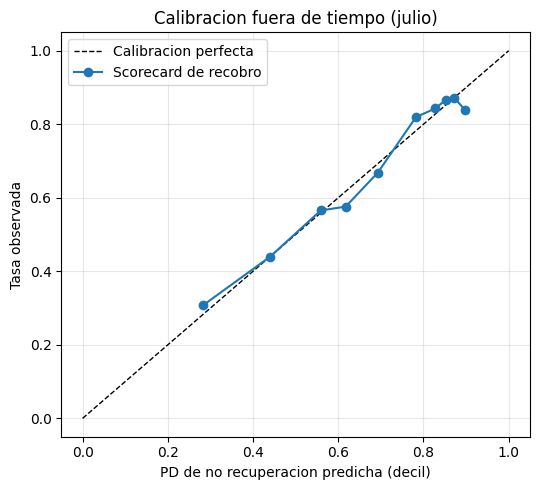

In [8]:
cols = modelo.binning_process_.variable_names


def predecir(datos):
    """PD de no recuperacion. Si algun valor deja el WOE sin definir, se le asigna WOE 0
    (sin informacion), como hace optbinning con las categorias desconocidas, y se avisa."""
    woe = modelo.binning_process_.transform(datos[cols], metric='woe')
    sin_definir = woe.columns[woe.isna().any()].tolist()
    if sin_definir:
        print(f"Aviso: WOE sin definir en {sin_definir} "
              f"({int(woe.isna().any(axis=1).sum())} filas); se usa WOE 0")
    return modelo.estimator_.predict_proba(woe.fillna(0))[:, 1]


test['PD_no_recupera'] = predecir(test)
train['PD_no_recupera'] = predecir(train)


def ks(y, p):
    fpr, tpr, _ = roc_curve(y, p)
    return float(np.max(tpr - fpr))


y_te, p_te = test['evento'].values, test['PD_no_recupera'].values
nuevos = test['titular_nuevo'].values
auc_tr = roc_auc_score(train['evento'], train['PD_no_recupera'])
auc_te = roc_auc_score(y_te, p_te)

metricas = pd.DataFrame({
    'Train (abr-jun)': [auc_tr, 2 * auc_tr - 1, ks(train['evento'], train['PD_no_recupera']), np.nan],
    'Test (jul)':      [auc_te, 2 * auc_te - 1, ks(y_te, p_te), brier_score_loss(y_te, p_te)],
    'Test, solo nuevos': [roc_auc_score(y_te[nuevos], p_te[nuevos]),
                          2 * roc_auc_score(y_te[nuevos], p_te[nuevos]) - 1,
                          ks(y_te[nuevos], p_te[nuevos]),
                          brier_score_loss(y_te[nuevos], p_te[nuevos])],
}, index=['AUC', 'Gini', 'KS', 'Brier'])
display(metricas.round(4))

# Calibracion fuera de tiempo, por decil
cal = pd.DataFrame({'pd': p_te, 'y': y_te})
cal['decil'] = pd.qcut(cal['pd'].rank(method='first'), 10, labels=False) + 1
cal = cal.groupby('decil').agg(pd_media=('pd', 'mean'), tasa_observada=('y', 'mean'), titulares=('y', 'size'))
print("\n=== Calibracion por decil (julio) ===")
display(cal.round(3))
print(f"PD media {p_te.mean():.3f} | tasa observada {y_te.mean():.3f}")

plt.figure(figsize=(5.5, 5))
plt.plot([0, 1], [0, 1], 'k--', lw=1, label='Calibracion perfecta')
plt.plot(cal['pd_media'], cal['tasa_observada'], 'o-', label='Scorecard de recobro')
plt.xlabel('PD de no recuperacion predicha (decil)'); plt.ylabel('Tasa observada')
plt.title('Calibracion fuera de tiempo (julio)'); plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## ESTRATEGIAS DE RECOBRO

El modelo se traduce en tres estrategias, con cortes fijados en los terciles de la PD sobre el
**entrenamiento**, de modo que la evaluación en julio no interviene en su definición:

- **Recordatorio**: alta probabilidad de recuperarse sola. Basta con un aviso automático.
- **Plan de pagos**: probabilidad intermedia. El gestor contacta y ofrece fraccionar la deuda.
- **Gestión especializada**: baja probabilidad de recuperarse. Contacto prioritario y, si procede,
  refinanciación o recobro formal.

Como la mayoría de los titulares en mora no se recupera, el valor del modelo no está en encontrar a
quien no se recupera, sino en identificar a la minoría que lo hará sola, para no dedicarle una
gestión cara.

Cortes (sobre train): 0.664 y 0.793

=== Resultado observado en agosto por estrategia (mora de julio) ===


,titulares,no_se_recupera,empeora_90,saldo_medio,% de la mora
estrategia,,,,,
Recordatorio,1652,0.484,0.078,40331.447,43.212
Plan de pagos,523,0.742,0.071,21734.868,13.680
Gestion especializada,1648,0.856,0.075,62206.982,43.108


,% de la mora,% de los que se recuperan,% de los que no se recuperan
estrategia,,,
Recordatorio,43.2,69.6,30.8
Plan de pagos,13.7,11.0,14.9
Gestion especializada,43.1,19.3,54.3


Con un simple recordatorio se atiende al 43 % de la mora, donde esta el 70 % de quienes se recuperan solos.
La gestion especializada se concentra en el 43 % de la mora, donde esta el 54 % de quienes no se recuperan.

El paso a 90 dias apenas varia entre estrategias (7.1% a 7.8%): el modelo separa la recuperacion, no el agravamiento.


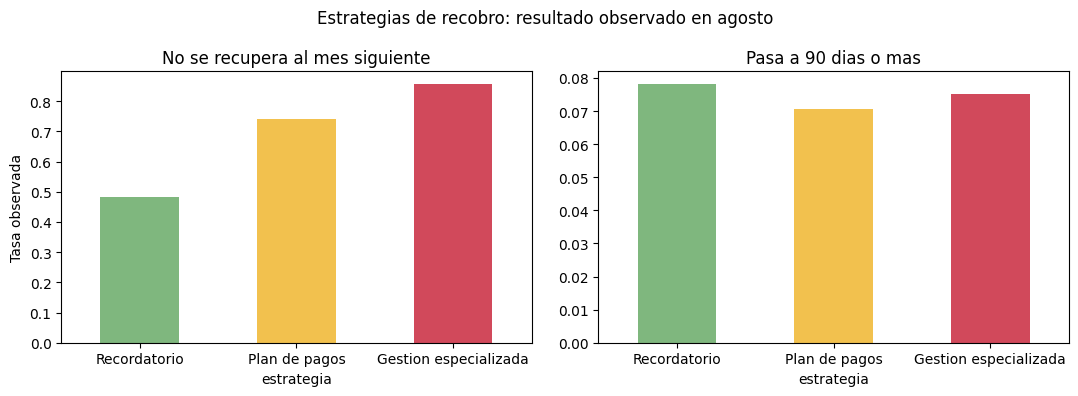

In [9]:
corte_1, corte_2 = np.quantile(train['PD_no_recupera'], [1/3, 2/3])
ESTRATEGIAS = ['Recordatorio', 'Plan de pagos', 'Gestion especializada']


def asignar_estrategia(pd_no_recupera):
    return pd.cut(pd_no_recupera, [-np.inf, corte_1, corte_2, np.inf], labels=ESTRATEGIAS)


test['estrategia'] = asignar_estrategia(test['PD_no_recupera'])
seg = test.groupby('estrategia', observed=True).agg(
    titulares=('ID', 'size'), no_se_recupera=('evento', 'mean'),
    empeora_90=('empeora_90', 'mean'), saldo_medio=('saldo', 'mean'))
seg['% de la mora'] = 100 * seg['titulares'] / seg['titulares'].sum()
print(f"Cortes (sobre train): {corte_1:.3f} y {corte_2:.3f}\n")
print("=== Resultado observado en agosto por estrategia (mora de julio) ===")
display(seg.round(3))

# Que parte de quienes se recuperan solos y de quienes no se recuperan cae en cada estrategia
recuperados = test[test['evento'] == 0].groupby('estrategia', observed=True).size()
no_recuperados = test[test['evento'] == 1].groupby('estrategia', observed=True).size()
seg['% de los que se recuperan'] = 100 * recuperados / recuperados.sum()
seg['% de los que no se recuperan'] = 100 * no_recuperados / no_recuperados.sum()
display(seg[['% de la mora', '% de los que se recuperan', '% de los que no se recuperan']].round(1))

r, g = seg.loc['Recordatorio'], seg.loc['Gestion especializada']
print(f"Con un simple recordatorio se atiende al {r['% de la mora']:.0f} % de la mora, donde esta el "
      f"{r['% de los que se recuperan']:.0f} % de quienes se recuperan solos.")
print(f"La gestion especializada se concentra en el {g['% de la mora']:.0f} % de la mora, donde esta el "
      f"{g['% de los que no se recuperan']:.0f} % de quienes no se recuperan.")
rango_90 = seg['empeora_90'].max() - seg['empeora_90'].min()
if rango_90 < 0.03:
    print(f"\nEl paso a 90 dias apenas varia entre estrategias ({seg['empeora_90'].min():.1%} a "
          f"{seg['empeora_90'].max():.1%}): el modelo separa la recuperacion, no el agravamiento.")

fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
seg['no_se_recupera'].plot.bar(ax=ejes[0], color=['#7fb77e', '#f2c14e', '#d1495b'])
ejes[0].set_title('No se recupera al mes siguiente'); ejes[0].set_ylabel('Tasa observada')
ejes[0].tick_params(axis='x', rotation=0)
seg['empeora_90'].plot.bar(ax=ejes[1], color=['#7fb77e', '#f2c14e', '#d1495b'])
ejes[1].set_title('Pasa a 90 dias o mas'); ejes[1].tick_params(axis='x', rotation=0)
plt.suptitle('Estrategias de recobro: resultado observado en agosto'); plt.tight_layout(); plt.show()

## ALERTAS PARA EL GESTOR Y PARA EL TITULAR

Se puntúa a los titulares en mora en agosto, el último mes con codificación consistente, y se
genera una alerta para cada uno. En producción se haría con el mes en curso.

- **Para el gestor**: la lista ordenada por **saldo en riesgo** (PD de no recuperación × saldo), que
  combina la probabilidad con lo que hay en juego, con la acción que corresponde a su estrategia.
- **Para el titular**: un mensaje adaptado a su situación. Igual que en los agentes, el texto se
  genera en código a partir de la estrategia y nunca lo redacta un modelo de lenguaje.

In [10]:
MENSAJES = {
    'Recordatorio': ('Recordatorio automatico',
        'Tu ultimo recibo esta pendiente. Si lo abonas en los proximos dias, tu tarjeta '
        'seguira funcionando con normalidad.'),
    'Plan de pagos': ('Llamada del gestor con propuesta de fraccionamiento',
        'Tienes un recibo pendiente. Podemos ayudarte a fraccionarlo: contacta con tu gestor '
        'para estudiar un plan de pagos adaptado a tu situacion.'),
    'Gestion especializada': ('Contacto prioritario y estudio de refinanciacion',
        'Tu tarjeta acumula recibos pendientes. Es importante que contactes con nosotros para '
        'buscar una solucion antes de que la deuda aumente.'),
}

agosto['PD_no_recupera'] = predecir(agosto)
agosto['estrategia'] = asignar_estrategia(agosto['PD_no_recupera'])
agosto['saldo_en_riesgo'] = (agosto['PD_no_recupera'] * agosto['saldo']).round(2)
agosto['accion_gestor'] = agosto['estrategia'].map(lambda e: MENSAJES[e][0])
agosto['mensaje_titular'] = agosto['estrategia'].map(lambda e: MENSAJES[e][1])

alertas = (agosto.sort_values('saldo_en_riesgo', ascending=False)
                 [['ID', 'PD_no_recupera', 'saldo', 'saldo_en_riesgo', 'estrategia',
                   'accion_gestor', 'mensaje_titular']]
                 .reset_index(drop=True))
alertas.index = alertas.index + 1
alertas.index.name = 'prioridad'

print("=== Alertas por estrategia (mora de agosto) ===")
display(alertas['estrategia'].value_counts().reindex(ESTRATEGIAS).to_frame('titulares'))
print("\n=== Las 10 alertas prioritarias para el gestor ===")
display(alertas.head(10)[['ID', 'PD_no_recupera', 'saldo', 'saldo_en_riesgo', 'estrategia', 'accion_gestor']].round(3))
print("\nEjemplo de mensaje al titular:")
print(f"  [{alertas.iloc[0]['estrategia']}] {alertas.iloc[0]['mensaje_titular']}")

=== Alertas por estrategia (mora de agosto) ===


,titulares
estrategia,
Recordatorio,1604
Plan de pagos,682
Gestion especializada,1669



=== Las 10 alertas prioritarias para el gestor ===


,ID,PD_no_recupera,saldo,saldo_en_riesgo,estrategia,accion_gestor
prioridad,,,,,,
1,25147,0.887,539418.0,478376.11,Gestion especializada,Contacto prioritario y estudio de refinanciacion
2,27468,0.887,534289.0,473827.52,Gestion especializada,Contacto prioritario y estudio de refinanciacion
3,20893,0.855,552234.0,472404.48,Gestion especializada,Contacto prioritario y estudio de refinanciacion
4,4324,0.824,504834.0,415879.27,Gestion especializada,Contacto prioritario y estudio de refinanciacion
5,15594,0.869,467150.0,406061.86,Gestion especializada,Contacto prioritario y estudio de refinanciacion
6,1993,0.824,470915.0,387891.32,Gestion especializada,Contacto prioritario y estudio de refinanciacion
7,27035,0.887,436968.0,387519.61,Gestion especializada,Contacto prioritario y estudio de refinanciacion
8,6995,0.849,415276.0,352551.78,Gestion especializada,Contacto prioritario y estudio de refinanciacion
9,16520,0.878,395881.0,347414.12,Gestion especializada,Contacto prioritario y estudio de refinanciacion



Ejemplo de mensaje al titular:
  [Gestion especializada] Tu tarjeta acumula recibos pendientes. Es importante que contactes con nosotros para buscar una solucion antes de que la deuda aumente.


## EXPORTACIÓN

In [11]:
joblib.dump(modelo, 'recobro_modelo.pkl')
joblib.dump({'cortes_estrategia': [float(corte_1), float(corte_2)],
             'estrategias': ESTRATEGIAS, 'mensajes': MENSAJES,
             'variables': list(cols)}, 'recobro_config.pkl')
alertas.to_excel('alertas_recobro.xlsx')

with zipfile.ZipFile('artefactos_recobro.zip', 'w', zipfile.ZIP_DEFLATED) as z:
    for f in ('recobro_modelo.pkl', 'recobro_config.pkl', 'alertas_recobro.xlsx'):
        z.write(f)
print("Exportado: recobro_modelo.pkl, recobro_config.pkl, alertas_recobro.xlsx")
print("Empaquetado en artefactos_recobro.zip")

try:
    from google.colab import files
    files.download('artefactos_recobro.zip')
except ImportError:
    pass

Exportado: recobro_modelo.pkl, recobro_config.pkl, alertas_recobro.xlsx
Empaquetado en artefactos_recobro.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## CONCLUSIONES Y LIMITACIONES

El modelo complementa al scorecard de comportamiento: aquel decide a quién vigilar, este decide
cómo actuar con quien ya está en mora. Las tablas anteriores permiten leer tres resultados:

- **Si ordena bien fuera de tiempo**, comparando el AUC de julio con el de la validación cruzada, y
  si se mantiene con los titulares nuevos.
- **Si está calibrado**, con el *backtesting* por decil: la PD de no recuperación se puede usar
  directamente para estimar el saldo en riesgo.
- **Si las estrategias separan de verdad**, con las tasas observadas por segmento y con qué parte de
  quienes se recuperan solos queda en el segmento de recordatorio, el de menor coste.
- **Si el modelo anticipa también el agravamiento**, con la tasa de paso a 90 días por estrategia. Si
  apenas varía, el modelo separa la recuperación pero no el paso a *default*, y anticiparlo exigiría
  un segundo modelo con ese evento.

**Limitaciones:**

- El desenlace es recuperarse al mes siguiente, no el recobro completo de la deuda: el dataset no
  tiene importes recuperados, así que no permite estimar una LGD de recobro.
- La evaluación es fuera de tiempo pero no del todo fuera de población: muchos titulares de julio
  ya estuvieron en mora antes. Por eso se mide también sobre los titulares nuevos.
- La mora observada es en la práctica de dos meses, por la codificación del dataset.
- Las estrategias y los mensajes son una propuesta de gestión: su efecto real habría que medirlo con
  un experimento, comparando titulares contactados y no contactados.